# 04 Can't pay versus won't pay

Bound the number of non-paying households that could afford to pay, using three assumptions about who the non-payers are.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[2]      # repo root, two levels above this folder
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.common.config import load_config
from src.common.pipeline import build

cfg = load_config()
MODE = os.environ.get("DATA_MODE")          # None = use config; "synthetic" = fake
ghs, ies, nfcm = build(MODE, save=False)

C:\Users\mmjmo\Projects\sa-electricity-nonpayment\src\common\pipeline.py:28: UnicodeWarning: 
One or more strings in the dta file could not be decoded using utf-8, and
so the fallback encoding of latin-1 is being used.  This can happen when a file
has been incorrectly encoded by Stata or some other software. You should verify
the string values returned are correct.
  return pd.read_stata(full, convert_categoricals=False)


In [2]:
from src.a_who_pays import split

nonpayers = split.nonpayers_by_province(ghs)
nonpayers

province
Eastern Cape     3.108730e+05
Free State       3.096264e+04
Gauteng          1.403525e+06
KwaZulu-Natal    3.647087e+05
Limpopo          8.714546e+04
Mpumalanga       1.533190e+05
North West       1.977149e+05
Northern Cape    1.656860e+04
Western Cape     1.038181e+05
Name: weight, dtype: float64

In [3]:
rows = []
for t in cfg["thresholds"]["bill_to_income"]:
    bounds = split.unable_bounds(ies, nonpayers, t)
    rows.append(split.split_summary(bounds, t))
summary = pd.DataFrame(rows)
summary

,threshold,nonpaying_households,able_to_pay_low,able_to_pay_mid,able_to_pay_high,able_share_low,able_share_mid,able_share_high
0,0.08,2.668635e+06,1.067719e+06,2.004068e+06,2.572997e+06,0.400099,0.750971,0.964162
1,0.10,2.668635e+06,1.345254e+06,2.166408e+06,2.630351e+06,0.504098,0.811804,0.985654
2,0.12,2.668635e+06,1.566778e+06,2.275535e+06,2.654327e+06,0.587108,0.852696,0.994638


Report low-to-high range. The mid case assumes non-payers look like all households with a bill.

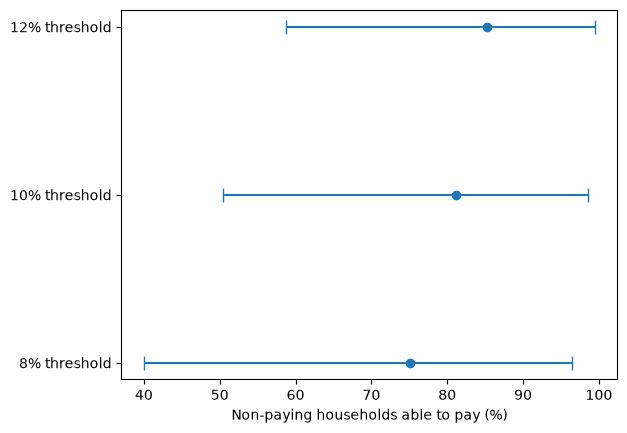

In [4]:
labels = [f"{t * 100:.0f}% threshold" for t in summary["threshold"]]
mid = summary["able_share_mid"] * 100
low = mid - summary["able_share_low"] * 100
high = summary["able_share_high"] * 100 - mid
plt.errorbar(mid, labels, xerr=[low, high], fmt="o", capsize=5)
plt.xlabel("Non-paying households able to pay (%)")
plt.show()

In [5]:
# Who are the non-paying households? Breakdown by main source of electricity (raw GHS file)
from src.common.pipeline import normalise_province, read_table

raw = read_table(cfg["paths"]["ghs"])
w = cfg["column_map"]["ghs"]["weight"]
labels = {1: "In-house conventional meter", 2: "In-house prepaid meter",
          3: "Neighbour's line, household pays", 4: "Neighbour's line, household does not pay"}
answered = raw[raw["eng_pay"].isin([1, 2])]
t = answered.pivot_table(index="eng_mainelect", columns="eng_pay", values=w, aggfunc="sum", fill_value=0)
t = t.rename(index=labels)
pd.DataFrame({"households_m": ((t[1] + t[2]) / 1e6).round(2),
              "non_paying_m": (t[2] / 1e6).round(2),
              "non_paying_%": (t[2] / (t[1] + t[2]) * 100).round(1)})

C:\Users\mmjmo\Projects\sa-electricity-nonpayment\src\common\pipeline.py:28: UnicodeWarning: 
One or more strings in the dta file could not be decoded using utf-8, and
so the fallback encoding of latin-1 is being used.  This can happen when a file
has been incorrectly encoded by Stata or some other software. You should verify
the string values returned are correct.
  return pd.read_stata(full, convert_categoricals=False)


,households_m,non_paying_m,non_paying_%
eng_mainelect,,,
In-house conventional meter,2.08,0.41,19.7
In-house prepaid meter,15.29,1.74,11.3
"Neighbour's line, household pays",0.50,0.24,47.7
"Neighbour's line, household does not pay",0.31,0.28,92.5


### Who are the non-payers, and does that change the answer?
About 1.74 million of the 2.67 million are on prepaid meters (11.3% of prepaid households), and about 0.41 million on conventional meters (19.7%). Another 0.52 million use a neighbour's line: 0.28 million say they do not pay (92.5% of that group) and 0.24 million say they pay their neighbour but answered "No" to paying for electricity, which looks inconsistent. Prepaid households answering "No" is puzzling, because they buy electricity as they use it. They may be answering for free basic units or electricity included in rent, or the meter may be bypassed, and I cannot tell which. If I count only non-payers with their own meter (2.14 million), the range at 10% falls to about 0.98 to 2.13 million, with a middle case of 1.74 million. The conclusion that a large share could afford a bill holds either way, but the numbers are smaller.

In [6]:
# Sensitivity: count only non-payers who have their own meter (conventional or prepaid)
raw["province_name"] = normalise_province(raw[cfg["column_map"]["ghs"]["province"]])
own_meter = raw[(raw["eng_pay"] == 2) & (raw["eng_mainelect"].isin([1, 2]))]
nonpayers_own = own_meter.groupby("province_name")[w].sum()
print(f"Non-payers with their own meter: {nonpayers_own.sum() / 1e6:.2f} million")
rows_own = []
for t_line in cfg["thresholds"]["bill_to_income"]:
    rows_own.append(split.split_summary(split.unable_bounds(ies, nonpayers_own, t_line), t_line))
pd.DataFrame(rows_own)[["threshold", "nonpaying_households", "able_to_pay_low", "able_to_pay_mid", "able_to_pay_high"]].round(0)

Non-payers with their own meter: 2.14 million


,threshold,nonpaying_households,able_to_pay_low,able_to_pay_mid,able_to_pay_high
0,0.0,2144481.0,746209.0,1610830.0,2092868.0
1,0.0,2144481.0,981942.0,1741331.0,2129641.0
2,0.0,2144481.0,1179825.0,1829305.0,2139900.0


### How many non-paying households could afford to pay?
About 2.67 million households say they do not pay for electricity. We cannot link the two surveys, so I give a range under three assumptions about who the non-payers are. At the 10% line, between about 1.35 million (if they are the poorest households with a bill) and about 2.63 million (if they are the richest) could afford a bill, with a middle case of about 2.17 million (if they look like typical payers). The range is wide because the data cannot tell us who the non-payers are, and it moves with the line: at 8% the middle case is about 2.0 million and at 12% about 2.28 million. The low end is the most cautious, because non-payers are probably poorer than average.

### Limits 
1. The two surveys cannot be linked household by household, so the split is a range under stated assumptions and not a measurement.
2. Consumption covered by free basic units, electricity included in rent, or a bypassed meter. The survey cannot separate them.
3. The bills I use are those of households that pay, so I do not know what a non-paying household would actually use.
4. The income survey is from 2022/23 and the household survey from 2025, and tariffs rose in between.
5. "Able to pay" means a bill below the chosen share of income. It does not mean willing to pay.